In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv("household_power_consumption.txt", sep = ";", low_memory=False)

In [3]:
data

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
2075254,26/11/2010,20:58:00,0.946,0.000,240.430,4.000,0.000,0.000,0.0
2075255,26/11/2010,20:59:00,0.944,0.000,240.000,4.000,0.000,0.000,0.0
2075256,26/11/2010,21:00:00,0.938,0.000,239.820,3.800,0.000,0.000,0.0
2075257,26/11/2010,21:01:00,0.934,0.000,239.700,3.800,0.000,0.000,0.0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB


In [5]:
data.describe()

,Sub_metering_3
count,2.049280e+06
mean,6.458447e+00
std,8.437154e+00
min,0.000000e+00
25%,0.000000e+00
50%,1.000000e+00
75%,1.700000e+01
max,3.100000e+01


# Exploratory Data Analysis (EDA)

In [7]:
# # Exploratory Data Analysis (EDA)

import plotly.express as px
import plotly.graph_objects as go

# Create a separate copy for EDA
data_eda = data.copy(deep=True)

# Numeric columns
numeric_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

In [8]:
# Replace invalid values with NaN
data_eda[numeric_cols] = data_eda[numeric_cols].replace('?', np.nan)

# Convert numeric columns
for col in numeric_cols:
    data_eda[col] = pd.to_numeric(data_eda[col], errors='coerce')

# Create datetime column
data_eda['Datetime'] = pd.to_datetime(
    data_eda['Date'] + ' ' + data_eda['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

data_eda = data_eda.set_index('Datetime').sort_index()

# Extract temporal features for EDA
data_eda['hour'] = data_eda.index.hour
data_eda['day_of_week'] = data_eda.index.dayofweek
data_eda['month'] = data_eda.index.month
data_eda['year'] = data_eda.index.year

data_eda.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,day_of_week,month,year
Datetime,,,,,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,5,12,2006
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,5,12,2006
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,5,12,2006
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,5,12,2006
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,5,12,2006


# Missing Values Analysis

In [9]:
# %%
missing_summary = pd.DataFrame({
    'Missing Values': data_eda.isnull().sum(),
    'Percentage': data_eda.isnull().mean() * 100
})

display(
    missing_summary.sort_values(
        'Percentage',
        ascending=False
    )
)

,Missing Values,Percentage
Global_active_power,25979,1.251844
Voltage,25979,1.251844
Global_reactive_power,25979,1.251844
Sub_metering_1,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_2,25979,1.251844
Sub_metering_3,25979,1.251844
Time,0,0.000000
Date,0,0.000000
hour,0,0.000000


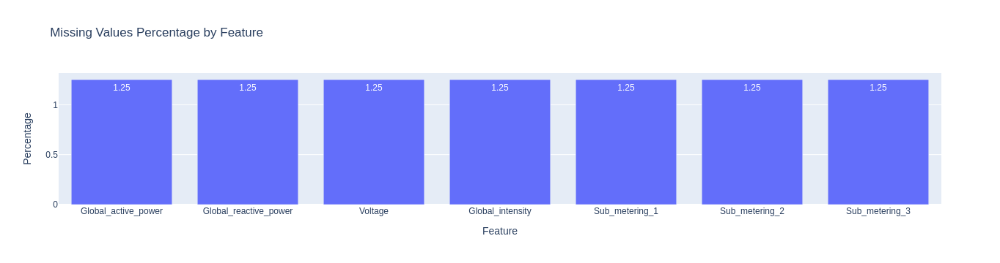

In [10]:
missing_plot = missing_summary[
    missing_summary['Missing Values'] > 0
].reset_index(names='Feature')

fig = px.bar(
    missing_plot,
    x='Feature',
    y='Percentage',
    title='Missing Values Percentage by Feature',
    text_auto='.2f'
)

fig.show()

# Target Variable Analysis

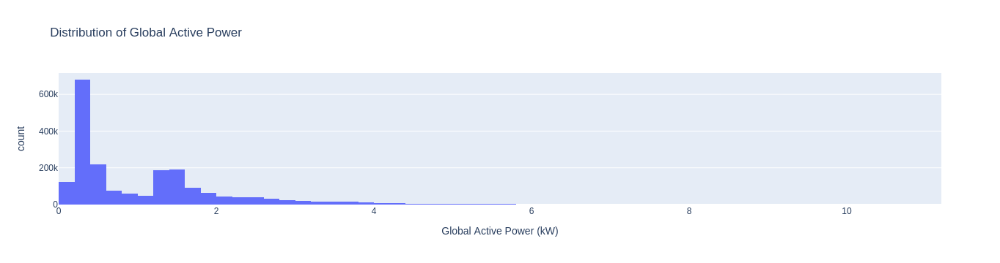

In [11]:
fig = px.histogram(
    data_eda,
    x='Global_active_power',
    nbins=100,
    title='Distribution of Global Active Power',
    labels={
        'Global_active_power': 'Global Active Power (kW)'
    }
)

fig.show()

# Hourly Consumption

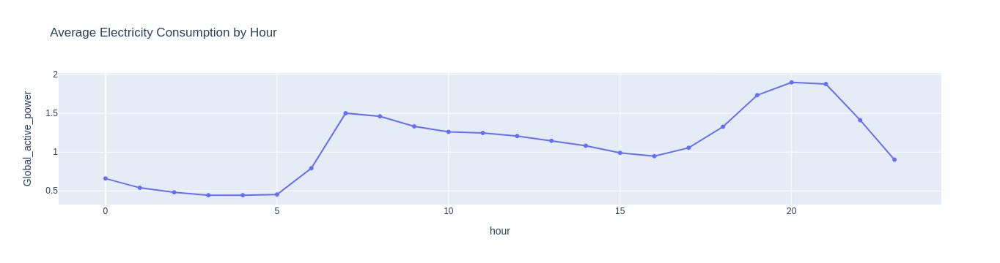

In [12]:
# %%
hourly_consumption = (
    data_eda.groupby('hour')['Global_active_power']
    .mean()
    .reset_index()
)

fig = px.line(
    hourly_consumption,
    x='hour',
    y='Global_active_power',
    markers=True,
    title='Average Electricity Consumption by Hour'
)

fig.show()

# Daily Consumption

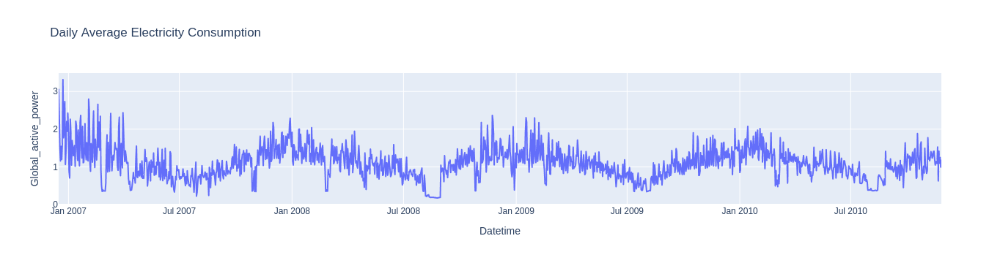

In [13]:
# %%
daily_consumption = (
    data_eda['Global_active_power']
    .resample('D')
    .mean()
    .dropna()
    .reset_index()
)

fig = px.line(
    daily_consumption,
    x='Datetime',
    y='Global_active_power',
    title='Daily Average Electricity Consumption'
)

fig.show()

# Monthly Consumption

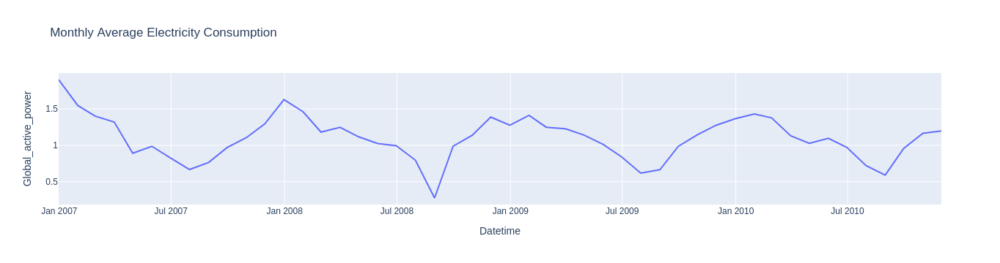

In [14]:
# %%
monthly_consumption = (
    data_eda['Global_active_power']
    .resample('ME')
    .mean()
    .dropna()
    .reset_index()
)

fig = px.line(
    monthly_consumption,
    x='Datetime',
    y='Global_active_power',
    title='Monthly Average Electricity Consumption'
)

fig.show()

# Consumption by Day of Week

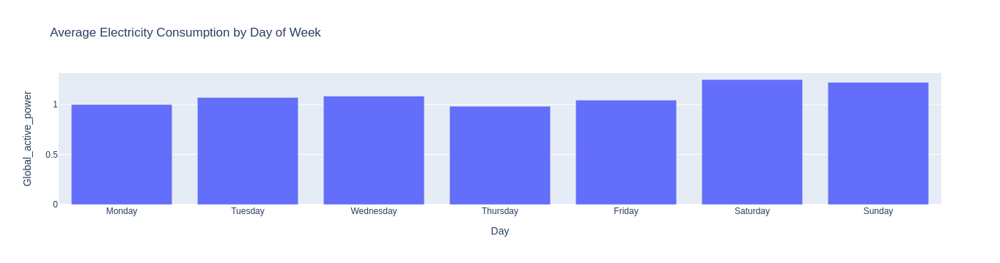

In [15]:
# %%
weekday_consumption = (
    data_eda.groupby('day_of_week')['Global_active_power']
    .mean()
    .reset_index()
)

weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

weekday_consumption['Day'] = (
    weekday_consumption['day_of_week'].map(weekday_names)
)

fig = px.bar(
    weekday_consumption,
    x='Day',
    y='Global_active_power',
    title='Average Electricity Consumption by Day of Week'
)

fig.show()

# Feature Relationships

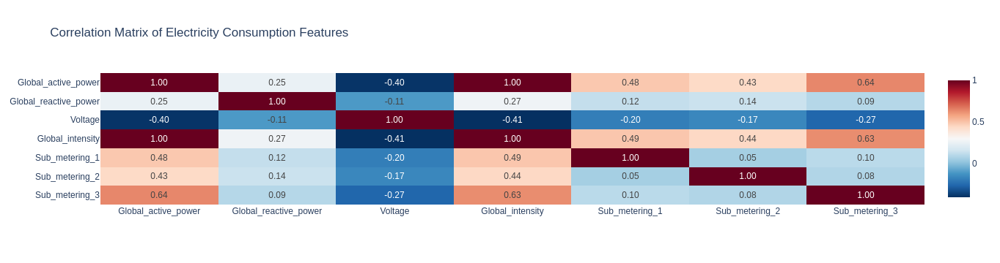

In [16]:
# %%
correlation = data_eda[numeric_cols].corr()

fig = px.imshow(
    correlation,
    text_auto='.2f',
    aspect='auto',
    color_continuous_scale='RdBu_r',
    title='Correlation Matrix of Electricity Consumption Features'
)

fig.show()

# Active Power vs Reactive Power

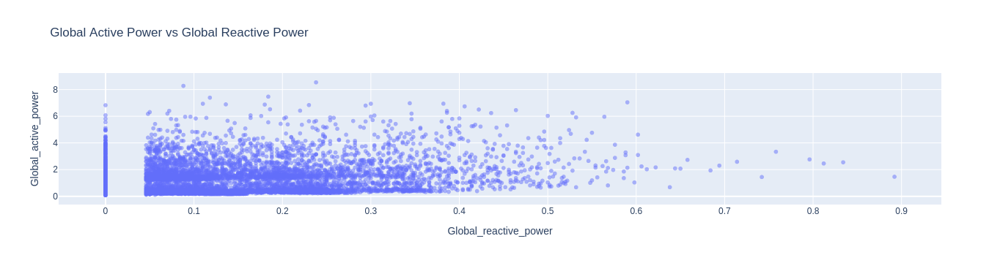

In [17]:
# %%
sample_data = data_eda[
    ['Global_active_power', 'Global_reactive_power']
].dropna().sample(
    n=min(10000, data_eda[['Global_active_power',
                           'Global_reactive_power']].dropna().shape[0]),
    random_state=42
)

fig = px.scatter(
    sample_data,
    x='Global_reactive_power',
    y='Global_active_power',
    title='Global Active Power vs Global Reactive Power',
    opacity=0.5
)

fig.show()

# Active Power vs Voltage

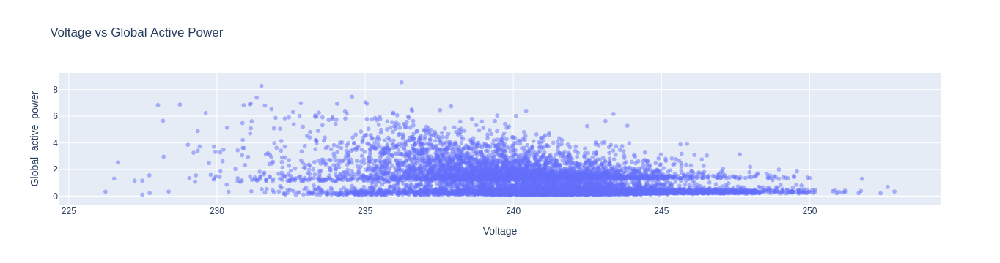

In [18]:
# %%
sample_voltage = data_eda[
    ['Voltage', 'Global_active_power']
].dropna().sample(
    n=min(10000, data_eda[['Voltage',
                           'Global_active_power']].dropna().shape[0]),
    random_state=42
)

fig = px.scatter(
    sample_voltage,
    x='Voltage',
    y='Global_active_power',
    title='Voltage vs Global Active Power',
    opacity=0.5
)

fig.show()

# Sub-metering Analysis

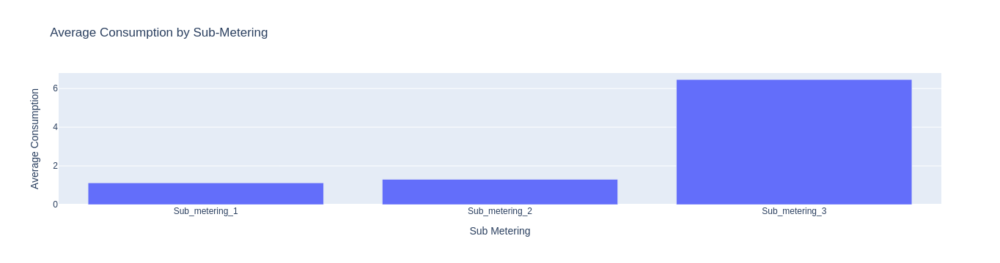

In [19]:
sub_metering_cols = [
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

sub_metering_means = (
    data_eda[sub_metering_cols]
    .mean()
    .reset_index()
)

sub_metering_means.columns = ['Sub Metering', 'Average Consumption']

fig = px.bar(
    sub_metering_means,
    x='Sub Metering',
    y='Average Consumption',
    title='Average Consumption by Sub-Metering'
)

fig.show()

In [20]:
data_eda['Global_active_power'].describe()

count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

In [21]:
missing_summary.sort_values(
    'Percentage',
    ascending=False
).round(2)

,Missing Values,Percentage
Global_active_power,25979,1.25
Voltage,25979,1.25
Global_reactive_power,25979,1.25
Sub_metering_1,25979,1.25
Global_intensity,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25
Time,0,0.00
Date,0,0.00
hour,0,0.00


In [22]:
hourly_consumption.sort_values(
    'Global_active_power',
    ascending=False
).head(5)

,hour,Global_active_power
20,20,1.899064
21,21,1.877697
19,19,1.733335
7,7,1.502246
8,8,1.461016


In [23]:
hourly_consumption.sort_values(
    'Global_active_power'
).head(5)

,hour,Global_active_power
4,4,0.443847
3,3,0.444866
5,5,0.453674
2,2,0.480621
1,1,0.539325


In [24]:
weekday_consumption[['Day', 'Global_active_power']].round(3)

,Day,Global_active_power
0,Monday,1.000
1,Tuesday,1.070
2,Wednesday,1.083
3,Thursday,0.982
4,Friday,1.043
5,Saturday,1.248
6,Sunday,1.220


In [25]:
monthly_consumption['Global_active_power'].describe()

count    48.000000
mean      1.099267
std       0.299240
min       0.276488
25%       0.966099
50%       1.123024
75%       1.280010
max       1.901295
Name: Global_active_power, dtype: float64

In [26]:
correlation.round(3)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.000,0.247,-0.400,0.999,0.484,0.435,0.639
Global_reactive_power,0.247,1.000,-0.112,0.266,0.123,0.139,0.090
Voltage,-0.400,-0.112,1.000,-0.411,-0.196,-0.167,-0.268
Global_intensity,0.999,0.266,-0.411,1.000,0.489,0.440,0.627
Sub_metering_1,0.484,0.123,-0.196,0.489,1.000,0.055,0.103
Sub_metering_2,0.435,0.139,-0.167,0.440,0.055,1.000,0.081
Sub_metering_3,0.639,0.090,-0.268,0.627,0.103,0.081,1.000


In [27]:
print("Highest consumption months:")
print(
    monthly_consumption.nlargest(
        5, 'Global_active_power'
    )
)

print("\nLowest consumption months:")
print(
    monthly_consumption.nsmallest(
        5, 'Global_active_power'
    )
)

Highest consumption months:
     Datetime  Global_active_power
0  2006-12-31             1.901295
12 2007-12-31             1.626474
1  2007-01-31             1.546034
13 2008-01-31             1.459920
37 2010-01-31             1.430525

Lowest consumption months:
     Datetime  Global_active_power
20 2008-08-31             0.276488
44 2010-08-31             0.590778
31 2009-07-31             0.618121
32 2009-08-31             0.664619
7  2007-07-31             0.667367


In [28]:
print(
    "Rows with at least one missing value:",
    data_eda[numeric_cols].isna().any(axis=1).sum()
)

print(
    "Rows with all numeric values missing:",
    data_eda[numeric_cols].isna().all(axis=1).sum()
)

Rows with at least one missing value: 25979
Rows with all numeric values missing: 25979


# Feature Engineering

In [4]:
# Create a working copy
data_clean = data.copy(deep=True)

# Define numerical columns
numeric_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

# Replace invalid values and convert columns to numeric
data_clean[numeric_cols] = (
    data_clean[numeric_cols]
    .replace('?', np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Remove records with missing electrical measurements
data_clean.dropna(subset=numeric_cols, inplace=True)

print("Shape after removing missing values:", data_clean.shape)
print("Remaining missing values:")
print(data_clean[numeric_cols].isna().sum())

Shape after removing missing values: (2049280, 9)
Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [5]:
# Convert Datetime column to datetime format
data_clean['Datetime'] = pd.to_datetime(
    data_clean['Date'] + ' ' + data_clean['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

# Set Datetime as index
data_clean.set_index('Datetime', inplace=True)

# Sort records chronologically
data_clean.sort_index(inplace=True)

In [6]:
# Extract time-based features from Datetime index
data_clean['hour'] = data_clean.index.hour
data_clean['day'] = data_clean.index.day
data_clean['month'] = data_clean.index.month
data_clean['year'] = data_clean.index.year
data_clean['day_of_week'] = data_clean.index.dayofweek

In [7]:
# Calculate apparent power (VA)
data_clean['Apparent_Power'] = (
    data_clean['Voltage'] * data_clean['Global_intensity']
)

# Calculate power factor
# Global_active_power is measured in kW,
# while Apparent_Power is measured in VA.
data_clean['Power Factor'] = (
    data_clean['Global_active_power'] * 1000
    / data_clean['Apparent_Power'].replace(0, np.nan)
)

In [8]:
# Hour encoding
data_clean['hour_sin'] = np.sin(
    2 * np.pi * data_clean['hour'] / 24
)
data_clean['hour_cos'] = np.cos(
    2 * np.pi * data_clean['hour'] / 24
)

# Day of week encoding
data_clean['dayofweek_sin'] = np.sin(
    2 * np.pi * data_clean['day_of_week'] / 7
)
data_clean['dayofweek_cos'] = np.cos(
    2 * np.pi * data_clean['day_of_week'] / 7
)

# Month encoding
data_clean['month_sin'] = np.sin(
    2 * np.pi * (data_clean['month'] - 1) / 12
)
data_clean['month_cos'] = np.cos(
    2 * np.pi * (data_clean['month'] - 1) / 12
)

# Day of month encoding
data_clean['day_sin'] = np.sin(
    2 * np.pi * (data_clean['day'] - 1) / 31
)
data_clean['day_cos'] = np.cos(
    2 * np.pi * (data_clean['day'] - 1) / 31
)

In [9]:
# Remove original time components
cols_to_drop = [
    'Date', 'Time',
    'hour', 'day', 'month', 'day_of_week'
]

data_clean.drop(columns=cols_to_drop, inplace=True)

# Check the resulting dataset
print("Final shape:", data_clean.shape)
print("\nMissing values:")
print(data_clean.isna().sum())

data_clean.info()

Final shape: (2049280, 18)

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
year                     0
Apparent_Power           0
Power Factor             0
hour_sin                 0
hour_cos                 0
dayofweek_sin            0
dayofweek_cos            0
month_sin                0
month_cos                0
day_sin                  0
day_cos                  0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2049280 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 18 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3    

In [10]:
print("Shape:", data_clean.shape)

print("\nColumns:")
print(data_clean.columns.tolist())

print("\nMissing values:")
print(data_clean.isna().sum().sum())

Shape: (2049280, 18)

Columns:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'year', 'Apparent_Power', 'Power Factor', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'month_sin', 'month_cos', 'day_sin', 'day_cos']

Missing values:
0


In [10]:
outlier_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
    'Apparent_Power'
]

outlier_summary = []

for col in outlier_cols:
    Q1 = data_clean[col].quantile(0.25)
    Q3 = data_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data_clean[
        (data_clean[col] < lower_bound) |
        (data_clean[col] > upper_bound)
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': len(outliers),
        'Outliers Percentage': len(outliers) / len(data_clean) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    'Outliers Percentage',
    ascending=False
)

,Feature,Lower Bound,Upper Bound,Outliers Count,Outliers Percentage
4,Sub_metering_1,0.000,0.000,169105,8.251923
3,Global_intensity,-6.100,13.900,100961,4.926657
7,Apparent_Power,-1453.956,3322.396,99529,4.856779
0,Global_active_power,-1.522,3.358,94907,4.631236
5,Sub_metering_2,-1.500,2.500,77151,3.764786
2,Voltage,233.140,248.740,51067,2.491948
1,Global_reactive_power,-0.171,0.413,40420,1.972400
6,Sub_metering_3,-25.500,42.500,0,0.000000


In [11]:
inspect_cols = [
    'Global_active_power',
    'Global_intensity',
    'Voltage',
    'Sub_metering_1',
    'Apparent_Power'
]

for col in inspect_cols:
    print(f"\n{'='*60}")
    print(f"Feature: {col}")
    print(f"{'='*60}")

    print("Lowest values:")
    print(data_clean[col].nsmallest(5).values)

    print("\nHighest values:")
    print(data_clean[col].nlargest(5).values)

    print("\nStatistics:")
    print(data_clean[col].describe())


Feature: Global_active_power
Lowest values:
[0.076 0.076 0.076 0.076 0.076]

Highest values:
[11.122 10.67  10.65  10.536 10.348]

Statistics:
count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

Feature: Global_intensity
Lowest values:
[0.2 0.2 0.2 0.2 0.2]

Highest values:
[48.4 46.4 46.4 45.8 44.6]

Statistics:
count    2.049280e+06
mean     4.627759e+00
std      4.444396e+00
min      2.000000e-01
25%      1.400000e+00
50%      2.600000e+00
75%      6.400000e+00
max      4.840000e+01
Name: Global_intensity, dtype: float64

Feature: Voltage
Lowest values:
[223.2  223.49 223.85 223.99 224.19]

Highest values:
[254.15 253.94 253.75 253.65 253.61]

Statistics:
count    2.049280e+06
mean     2.408399e+02
std      3.239987e+00
min      2.232000e+02
25%      2.389900e+02
50%      2.410100e+02
75%      2.428900e+02
max      2.

In [13]:
data_clean_valut = data_clean.copy(deep=True)

In [14]:
from sklearn.ensemble import IsolationForest

outlier_features = [
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
    'Apparent_Power'
]

iso = IsolationForest(
    contamination=0.02,
    random_state=42
)

iso.fit(data_clean[outlier_features])

data_clean["outliers"] = iso.predict(
    data_clean[outlier_features]
)

outliers = data_clean[
    data_clean["outliers"] == -1
].copy()

normal_data = data_clean[
    data_clean["outliers"] == 1
].copy()

print("Outliers:", len(outliers))
print("Normal:", len(normal_data))

print(
    "Outliers Percentage:",
    len(outliers) / len(data_clean) * 100
)

print(
    "Normal Percentage:",
    len(normal_data) / len(data_clean) * 100
)

Outliers: 40986
Normal: 2008294
Outliers Percentage: 2.000019519050593
Normal Percentage: 97.99998048094942


In [15]:
comparison = pd.DataFrame({
    'Normal Mean': normal_data[outlier_features].mean(),
    'Outliers Mean': outliers[outlier_features].mean(),
    'Normal Median': normal_data[outlier_features].median(),
    'Outliers Median': outliers[outlier_features].median()
})

comparison

,Normal Mean,Outliers Mean,Normal Median,Outliers Median
Global_reactive_power,0.120890,0.262104,0.10,0.246
Voltage,240.936688,236.095225,241.07,236.060
Global_intensity,4.299461,20.714210,2.60,20.200
Sub_metering_1,0.708401,21.384326,0.00,33.000
Sub_metering_2,0.871010,22.246279,0.00,24.000
Sub_metering_3,6.328114,12.844703,1.00,17.000
Apparent_Power,1031.552783,4885.143954,606.58,4763.000


In [16]:
print("Normal Target:")
print(normal_data['Global_active_power'].describe())

print("\nOutliers Target:")
print(outliers['Global_active_power'].describe())

Normal Target:
count    2.008294e+06
mean     1.014558e+00
std      9.061844e-01
min      7.600000e-02
25%      3.060000e-01
50%      5.660000e-01
75%      1.494000e+00
max      8.310000e+00
Name: Global_active_power, dtype: float64

Outliers Target:
count    40986.000000
mean         4.867370
std          1.053002
min          1.762000
25%          4.212000
50%          4.748000
75%          5.454000
max         11.122000
Name: Global_active_power, dtype: float64


In [17]:
# Keep all observations
final_data = data_clean.copy(deep=True)

# Keep anomaly labels for analysis
final_data["outliers"] = iso.predict(
    final_data[outlier_features]
)

In [18]:
data_clean = data_clean_valut.copy(deep=True)

In [19]:
data_clean

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,year,Apparent_Power,Power Factor,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos,day_sin,day_cos
Datetime,,,,,,,,,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006,4321.056,0.975687,-0.965926,-0.258819,-0.974928,-0.222521,-0.500000,0.866025,0.101168,-0.994869
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006,5373.490,0.997490,-0.965926,-0.258819,-0.974928,-0.222521,-0.500000,0.866025,0.101168,-0.994869
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006,5365.670,1.001552,-0.965926,-0.258819,-0.974928,-0.222521,-0.500000,0.866025,0.101168,-0.994869
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006,5376.020,1.002228,-0.965926,-0.258819,-0.974928,-0.222521,-0.500000,0.866025,0.101168,-0.994869
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006,3723.744,0.984493,-0.965926,-0.258819,-0.974928,-0.222521,-0.500000,0.866025,0.101168,-0.994869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010-11-26 20:58:00,0.946,0.000,240.43,4.0,0.0,0.0,0.0,2010,961.720,0.983654,-0.866025,0.500000,-0.433884,-0.900969,-0.866025,0.500000,-0.937752,0.347305
2010-11-26 20:59:00,0.944,0.000,240.00,4.0,0.0,0.0,0.0,2010,960.000,0.983333,-0.866025,0.500000,-0.433884,-0.900969,-0.866025,0.500000,-0.937752,0.347305
2010-11-26 21:00:00,0.938,0.000,239.82,3.8,0.0,0.0,0.0,2010,911.316,1.029281,-0.707107,0.707107,-0.433884,-0.900969,-0.866025,0.500000,-0.937752,0.347305


# Feature Engineering

In [11]:
# Weekend feature
data_clean['is_weekend'] = (
    data_clean.index.dayofweek >= 5
).astype(int)

In [12]:
# Time period feature
hour = data_clean.index.hour

data_clean['time_period'] = pd.cut(
    hour,
    bins=[-1, 5, 11, 17, 23],
    labels=['Night', 'Morning', 'Afternoon', 'Evening']
)

In [13]:
# Season feature
month = data_clean.index.month

season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

data_clean['season'] = pd.Series(
    month.map(season_map),
    index=data_clean.index
)

In [14]:
print(data_clean[
    ['is_weekend', 'time_period', 'season']
].head())

print(data_clean[
    ['is_weekend', 'time_period', 'season']
].isnull().sum())

                     is_weekend time_period  season
Datetime                                           
2006-12-16 17:24:00           1   Afternoon  Winter
2006-12-16 17:25:00           1   Afternoon  Winter
2006-12-16 17:26:00           1   Afternoon  Winter
2006-12-16 17:27:00           1   Afternoon  Winter
2006-12-16 17:28:00           1   Afternoon  Winter
is_weekend     0
time_period    0
season         0
dtype: int64


In [15]:
print("Weekend Distribution:")
print(data_clean['is_weekend'].value_counts())

print("\nTime Period Distribution:")
print(data_clean['time_period'].value_counts())

print("\nSeason Distribution:")
print(data_clean['season'].value_counts())

Weekend Distribution:
is_weekend
0    1470428
1     578852
Name: count, dtype: int64

Time Period Distribution:
time_period
Evening      513146
Night        512375
Afternoon    512109
Morning      511650
Name: count, dtype: int64

Season Distribution:
season
Spring    524156
Summer    518290
Autumn    512922
Winter    493912
Name: count, dtype: int64


In [16]:
print("Shape:", data_clean.shape)

print("\nColumns:")
print(data_clean.columns.tolist())

Shape: (2049280, 21)

Columns:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'year', 'Apparent_Power', 'Power Factor', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'is_weekend', 'time_period', 'season']


In [17]:
target = "Global_active_power"

X = data_clean.drop(
    columns=[target, "Power Factor"],
    errors="ignore"
)

y = data_clean[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (2049280, 19)
y Shape: (2049280,)


In [18]:
categorical_features = [
    "time_period",
    "season"
]

In [19]:
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

In [20]:
print(X.shape)
print(y.shape)

print("\nCategorical Features:")
print(X[categorical_features].nunique())

print("\nMissing Values:")
print(X.isnull().sum().sum())
print(y.isnull().sum())

(2049280, 19)
(2049280,)

Categorical Features:
time_period    4
season         4
dtype: int64

Missing Values:
0
0


In [21]:
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1434496, 19) (1434496,)
Validation: (307392, 19) (307392,)
Test: (307392, 19) (307392,)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ],
    sparse_threshold=0
)

### Linear Regression

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

y_pred_lr = lr_pipeline.predict(X_val)

# HistGradientBoosting

In [31]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

hgb_pipeline.fit(X_train, y_train)

y_pred_hgb = hgb_pipeline.predict(X_val)

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{model_name}")
    print("-" * 35)
    print(f"MAE:  {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²:   {r2:.6f}")

evaluate_model(y_val, y_pred_lr, "Linear Regression")
evaluate_model(y_val, y_pred_hgb, "HistGradientBoosting")



Linear Regression
-----------------------------------
MAE:  0.021803
RMSE: 0.034334
R²:   0.998940

HistGradientBoosting
-----------------------------------
MAE:  0.018703
RMSE: 0.028095
R²:   0.999290


In [33]:
y_pred_test = hgb_pipeline.predict(X_test)

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_test = mean_absolute_error(y_test, y_pred_test)

rmse_test = np.sqrt(
    mean_squared_error(y_test, y_pred_test)
)

r2_test = r2_score(y_test, y_pred_test)

print("Final Test Results")
print("=" * 40)
print(f"MAE:  {mae_test:.6f}")
print(f"RMSE: {rmse_test:.6f}")
print(f"R²:   {r2_test:.6f}")

Final Test Results
MAE:  0.019197
RMSE: 0.030347
R²:   0.998760


# Feature Importance

In [38]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm_importance = permutation_importance(
    hgb_pipeline,
    X_val,
    y_val,
    n_repeats=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance,Std
7,Apparent_Power,0.765677,9.572130e-04
2,Global_intensity,0.291564,1.075516e-04
5,Sub_metering_3,0.010151,1.261594e-05
0,Global_reactive_power,0.004727,2.838858e-06
3,Sub_metering_1,0.004532,2.335105e-05
9,hour_cos,0.001287,1.312396e-05
1,Voltage,0.001113,6.646103e-06
13,month_cos,0.000704,5.056462e-06
4,Sub_metering_2,0.000698,8.742632e-06
17,time_period,0.000213,2.306070e-06


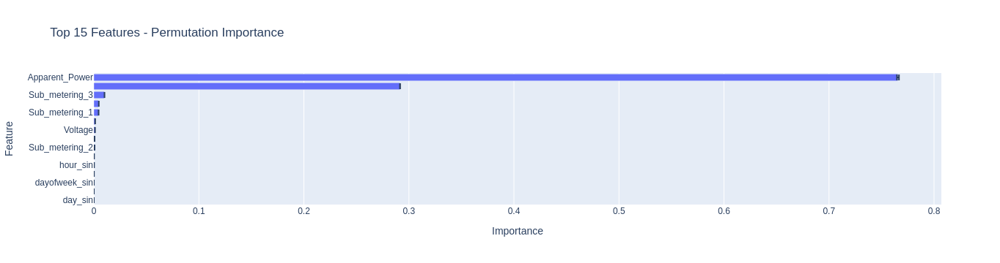

In [39]:
import plotly.express as px

fig = px.bar(
    feature_importance.head(15).sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 15 Features - Permutation Importance",
    error_x="Std"
)

fig.show()

# Fine Tuning

In [35]:
X_tune = X_train.iloc[::6].copy()
y_tune = y_train.iloc[::6].copy()

print("Tuning X:", X_tune.shape)
print("Tuning y:", y_tune.shape)

Tuning X: (239083, 19)
Tuning y: (239083,)


In [36]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        random_state=42,
        early_stopping=False
    ))
])

param_distributions = {
    "model__max_iter": [100, 150, 200, 250],
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_leaf_nodes": [15, 31, 50],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 1, 5]
}

In [37]:
tscv = TimeSeriesSplit(n_splits=3)

random_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=1
)

random_search.fit(X_tune, y_tune)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__l2_regularization': [0, 1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_iter': [100, 150, ...], 'model__max_leaf_nodes': [15, 31, ...], ...}"
,n_iter,8
,scoring,'neg_mean_absolute_error'
,n_jobs,1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [38]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV MAE:")
print(-random_search.best_score_)

Best Parameters:
{'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__max_iter': 250, 'model__learning_rate': 0.1, 'model__l2_regularization': 5}

Best CV MAE:
0.021767934629778694


In [39]:
best_hgb_pipeline = random_search.best_estimator_

best_hgb_pipeline.fit(X_train, y_train)

y_pred_tuned = best_hgb_pipeline.predict(X_val)

evaluate_model(
    y_val,
    y_pred_tuned,
    "Tuned HistGradientBoosting"
)


Tuned HistGradientBoosting
-----------------------------------
MAE:  0.018939
RMSE: 0.028400
R²:   0.999275


# Save the model

In [35]:
import pickle

In [40]:
output_file = f"power_model.pkl"

In [41]:
with open(output_file, 'wb') as f_out: 
    pickle.dump(hgb_pipeline, f_out)

In [43]:
import sys
import sklearn

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Scikit-learn path:", sklearn.__file__)

Python: 3.13.7 (main, Mar  3 2026, 12:19:54) [GCC 15.2.0]
Scikit-learn: 1.7.2
Scikit-learn path: /home/fayyad/.venvs/dev/lib/python3.13/site-packages/sklearn/__init__.py
